In [2]:
import numpy as np 
np.__version__

'2.4.1'

In [12]:
class Fuzzy_K_Means:
    def __init__(self, nbr_sommet, x, max_iter = 50, epsi = 0.001, flou_coef = 2):
        self.nbr_sommet = nbr_sommet
        self.x = np.asarray(x, dtype=float)
        if self.x.ndim == 1:
            self.x = self.x.reshape(-1, 1)
        self.nbr_point = len(x)
        self.max_iter = max_iter
        self.epsi = epsi
        self.flou_coef = flou_coef
        self.u_new = np.random.rand(self.nbr_sommet, self.nbr_point)
        self.u_new /= self.u_new.sum(axis=0)


    def critere_arret(self, u_anc,itr):
        cr = np.max(np.absolute(self.u_new - u_anc))
        if cr < self.epsi: 
            print(f"le critere d'arret est atteint apres {itr} iteration")
            return True
        else:
            return False

    def algorithme_fuzzy_k_means(self):
        
        val_clusters = np.zeros((self.nbr_sommet, np.shape(self.x)[1]))
        for iter in range(self.max_iter):
            mat_dist = np.zeros((self.nbr_sommet, self.nbr_point))
            u_anc = np.copy(self.u_new)
            for j in range(self.nbr_sommet):
                num = 0
                denom = 0
                for i in range (self.nbr_point):
                    num += self.u_new[j,i]**self.flou_coef * self.x[i]
                    denom += self.u_new[j,i]**self.flou_coef
                val_clusters[j] = num / denom

                for ii in range(self.nbr_point):
                    mat_dist[j,ii] = np.linalg.norm(self.x[ii] - val_clusters[j])
            mat_dist = np.maximum(mat_dist, 1e-10)
                       
            for j in range(self.nbr_sommet):
                for i in range(self.nbr_point):
                    som = 0
                    for k in range(self.nbr_sommet):
                       som += (mat_dist[j, i] / mat_dist[k, i]) ** (2 / (self.flou_coef - 1))
                    
                    self.u_new[j,i] = 1 / som
            print(f"ilteration num {iter}")
            if self.critere_arret(u_anc, iter):
                return self.u_new, val_clusters
            else:
                continue

        print("critere d'arret jamais atteint, mettre plus d'iteration.")
        return self.u_new, val_clusters
            


image : (100, 100, 3) -> X : (10000, 3)
ilteration num 0
ilteration num 1
ilteration num 2
ilteration num 3
ilteration num 4
ilteration num 5
ilteration num 6
ilteration num 7
ilteration num 8
ilteration num 9
ilteration num 10
ilteration num 11
ilteration num 12
ilteration num 13
ilteration num 14
ilteration num 15
ilteration num 16
ilteration num 17
ilteration num 18
ilteration num 19
ilteration num 20
ilteration num 21
ilteration num 22
ilteration num 23
ilteration num 24
ilteration num 25
ilteration num 26
ilteration num 27
ilteration num 28
ilteration num 29
ilteration num 30
ilteration num 31
ilteration num 32
ilteration num 33
ilteration num 34
ilteration num 35
ilteration num 36
ilteration num 37
ilteration num 38
ilteration num 39
ilteration num 40
ilteration num 41
ilteration num 42
ilteration num 43
ilteration num 44
ilteration num 45
ilteration num 46
ilteration num 47
ilteration num 48
ilteration num 49
critere d'arret jamais atteint, mettre plus d'iteration.


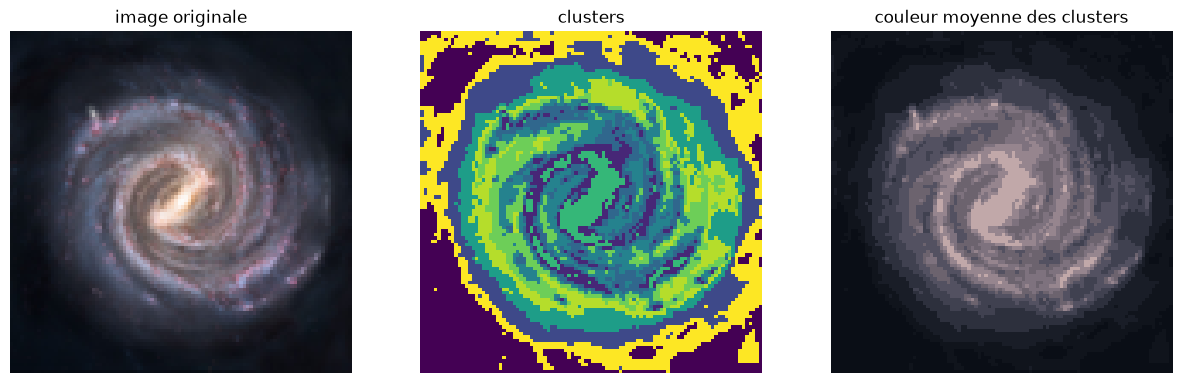

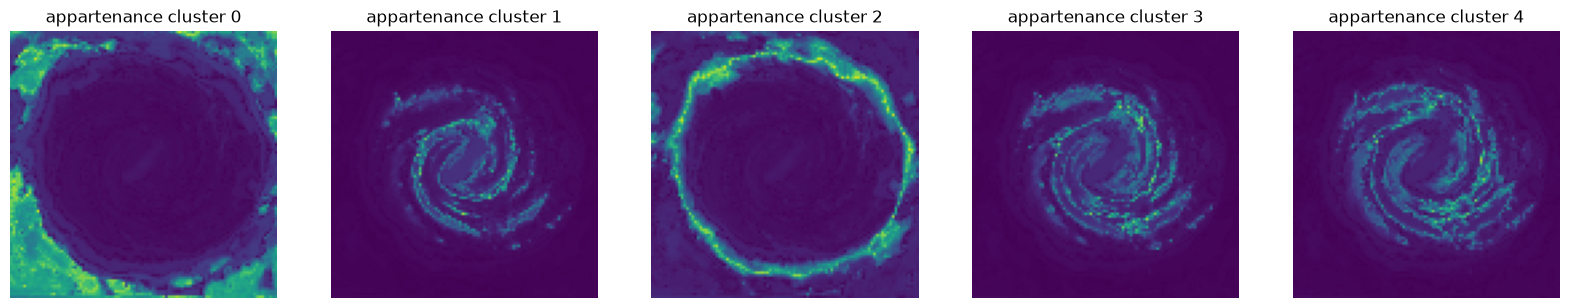

In [13]:
from PIL import Image
import matplotlib.pyplot as plt

PATH_IMG_EN = "/home/azouaou/Master_2_VMI/etudes/reconnaissance_de_forme_avancee/milky-way.jpg"
PATH_IMG_SO = "/home/azouaou/Master_2_VMI/etudes/reconnaissance_de_forme_avancee/milky-way_fkm.png"

# lecture + réduction de l'image (sinon trop lent avec les boucles)
img = np.array(Image.open(PATH_IMG_EN).convert("RGB").resize((100, 100)))
H, W = img.shape[0], img.shape[1]
X = img.reshape(-1, 3)
print("image :", img.shape, "-> X :", X.shape)

# fuzzy c-means
fkm = Fuzzy_K_Means(10, X, 50, 0.001, 3)
mat_poids, mat_clusters = fkm.algorithme_fuzzy_k_means()

# retour a l'image
classes = mat_poids.argmax(axis=0)
segmentation = classes.reshape(H, W)
image_segmentee = mat_clusters[classes].reshape(H, W, 3).astype(np.uint8)

# sauvegarde
Image.fromarray(image_segmentee).save(PATH_IMG_SO)

# affichage
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img)
ax[0].set_title("image originale")
ax[1].imshow(segmentation)
ax[1].set_title("clusters")
ax[2].imshow(image_segmentee)
ax[2].set_title("couleur moyenne des clusters")
for a in ax:
    a.axis("off")
plt.show()

# carte d'appartenance (flou) de chaque cluster
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for j in range(5):
    ax[j].imshow(mat_poids[j].reshape(H, W), cmap="viridis", vmin=0, vmax=1)
    ax[j].set_title(f"appartenance cluster {j}")
    ax[j].axis("off")
plt.show()